---
title: "3.5.b Amenaza por incendios de cobertura vegetal"
short_title: "b. Amenaza"
subtitle: "Focos de calor 2001–2025, pérdida de bosque y condiciones secas en el entorno de Leticia"
description: "Análisis de focos de calor de NASA FIRMS, pérdida de cobertura arbórea (Hansen) y meteorología seca alrededor de Leticia."
keywords: [incendios, FIRMS, MODIS, VIIRS, deforestación, Hansen, Leticia]
---

[![Abrir en Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/mromerot/leticia/blob/main/book/03_analisis/35_incendios/b_amenaza.ipynb)

In [1]:
# Preparación del entorno. En Colab instala el paquete del proyecto desde GitHub (1–2 minutos);
# en una copia local usa el paquete ya instalado con `pip install -e .`.
import sys, subprocess
if "google.colab" in sys.modules:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "leticia @ git+https://github.com/mromerot/leticia"], check=True)
from leticia.libro import preparar, intentar
preparar()

El bosque amazónico húmedo casi no arde de forma natural. El fuego llega con la **deforestación y las quemas
agrícolas** y se propaga cuando la sequía seca la hojarasca y el sotobosque. En 2024, el año de la vaciante
récord, la UNGRD registró en Leticia 14 incendios de cobertura vegetal, frente a uno o ninguno en años
anteriores (ver [1.7](../../01_conceptos/17_perfil_riesgos.ipynb)). Este cuaderno mide la amenaza con focos de
calor satelitales, la pérdida de bosque y las condiciones de sequía.

In [2]:
import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display
from matplotlib.patches import Patch

from leticia import aoi, clima, espacial, exposicion, fuentes, riesgo, viz
from leticia.config import parametros

pi = parametros()["incendios"]
urbana = aoi.area_urbana()
mun = fuentes.limite_municipal()


def focos(sensor="modis", anios=None):
    f = fuentes.focos_calor(sensor, anios)
    if sensor == "modis":
        f = f[f["confidence"] >= pi["confianza_modis_min"]]
    else:
        f = f[f["confidence"].astype(str).str.lower().isin(pi["confianza_viirs"])]
    f = f[f["type"] == 0] if "type" in f else f          # solo vegetación (excluye fuentes estáticas y volcanes)
    return gpd.GeoDataFrame(f, geometry=gpd.points_from_xy(f.longitude, f.latitude), crs=4326)

## 1. Focos de calor por año y por mes

Focos MODIS 2001–2025: 13 ; focos VIIRS 2012–2025: 82 . Año con más focos VIIRS: 2024 (16).

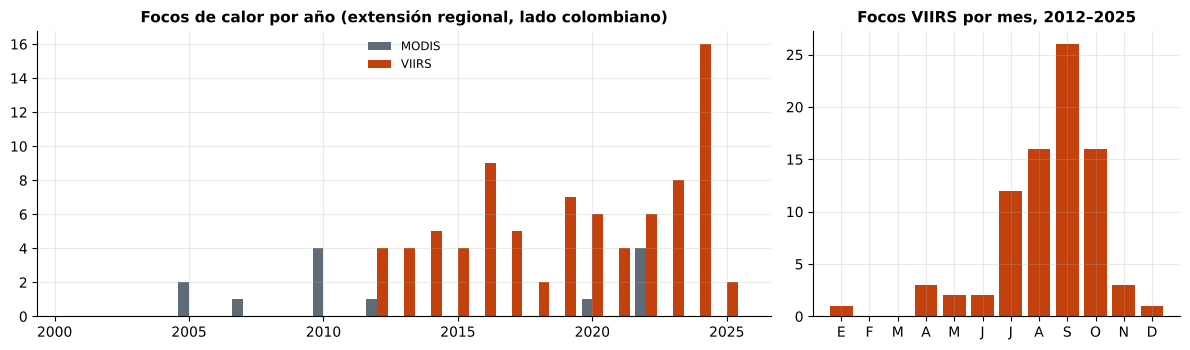

In [3]:
modis = focos("modis")
viirs = focos("viirs-snpp", list(range(2012, 2026)))
anual = pd.DataFrame({"MODIS (1 km)": modis.groupby(modis.index.year).size(),
                      "VIIRS (375 m)": viirs.groupby(viirs.index.year).size()}).reindex(range(2001, 2026)).fillna(0).astype(int)
anual.loc[anual.index < 2012, "VIIRS (375 m)"] = np.nan
mensual = viirs.groupby(viirs.index.month).size().reindex(range(1, 13), fill_value=0)
fig, ax = plt.subplots(1, 2, figsize=(12, 3.6), gridspec_kw={"width_ratios": [2, 1]})
x = anual.index.values
ax[0].bar(x - 0.2, anual["MODIS (1 km)"], width=0.4, color=viz.GRIS, label="MODIS")
ax[0].bar(x + 0.2, anual["VIIRS (375 m)"], width=0.4, color=viz.CALOR, label="VIIRS")
ax[0].set_title("Focos de calor por año (extensión regional, lado colombiano)")
ax[0].legend()
ax[1].bar(mensual.index, mensual, color=viz.CALOR)
ax[1].set_xticks(range(1, 13)); ax[1].set_xticklabels(list("EFMAMJJASOND"))
ax[1].set_title("Focos VIIRS por mes, 2012–2025")
fig.tight_layout()
display(Markdown(f"Focos MODIS 2001–2025: **{int(anual['MODIS (1 km)'].sum())}**; focos VIIRS 2012–2025: **{int(anual['VIIRS (375 m)'].sum())}**. "
                 f"Año con más focos VIIRS: **{int(anual['VIIRS (375 m)'].idxmax())}** ({int(anual['VIIRS (375 m)'].max())})."))

In [4]:
viz.pie(viz.nota_fuente("focos_calor") + " Giglio et al. (2016); Schroeder et al. (2014).")

Fuente: NASA FIRMS — Archivo anual por país, MODIS (1 km, 2001–) y VIIRS S-NPP (375 m, 2012–). Giglio et al. (2016); Schroeder et al. (2014).

**Lectura.** Comparado con el arco de deforestación de Brasil o con el piedemonte colombiano, el entorno de
Leticia tiene **pocos focos detectables**: los incendios son pequeños (quemas de rastrojo y potreros, fuegos de
sotobosque) y muchos escapan a sensores de 375 m–1 km. A escala mundial, contar los fuegos pequeños que no dejan
cicatriz visible en los productos de área quemada de 500 m aumenta el área quemada en cerca de 35 %
[@randerson2012]: los conteos de este cuaderno son un **mínimo**. Aun así, los años de sequía sobresalen, en especial 2024,
cuando la UNGRD registró 14 incendios de cobertura vegetal en el municipio. ThinkHazard clasifica la amenaza por
incendio forestal de Leticia como **baja** [@thinkhazard2024].

## 2. Dónde ocurren

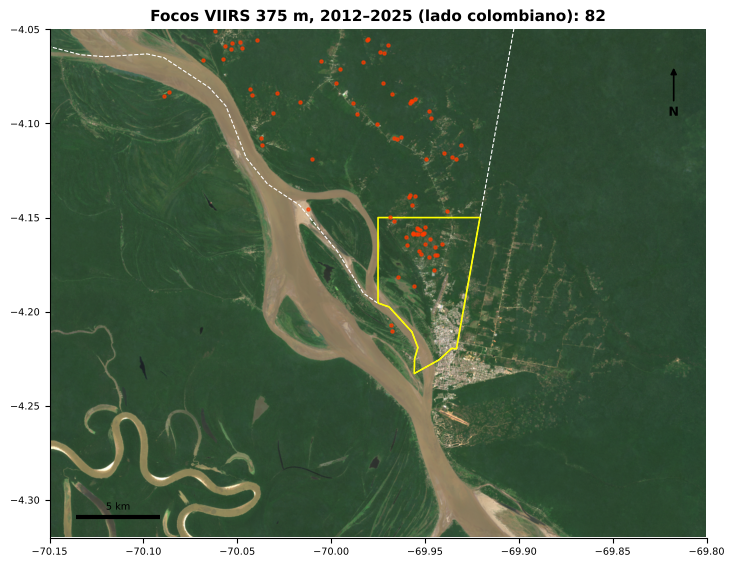

In [5]:
fig, ax = plt.subplots(figsize=(9, 6.6))
viz.fondo(ax, "bbox_regional")
mun.boundary.plot(ax=ax, color="white", lw=0.8, ls="--", zorder=2)
urbana.to_crs(4326).boundary.plot(ax=ax, color="yellow", lw=1.2, zorder=3)
if len(viirs):
    viirs.plot(ax=ax, markersize=5, color="#ff3b00", alpha=0.7, zorder=4)
viz.marco(ax, "bbox_regional", f"Focos VIIRS 375 m, 2012–2025 (lado colombiano): {len(viirs)}")

Los focos se alinean con la **vía Leticia–Tarapacá** y los caminos que salen de ella, donde avanza la frontera
agropecuaria, y con la periferia urbana. El archivo por país de FIRMS solo incluye focos en territorio
colombiano: los de Brasil y Perú, que también aportan humo, no aparecen en el mapa.

## 3. Puntos de calor y cicatrices de quema del SINCHI

El SIAT-AC del Instituto SINCHI publica a diario los puntos de calor de la Amazonia colombiana a partir de los datos
de la NASA (MODIS y VIIRS de los satélites S-NPP, NOAA-20 y NOAA-21) y señala la figura territorial donde cae cada
punto; además cartografía las **cicatrices de quema**, la huella que deja el fuego, a escala 1:100.000. A diferencia
del archivo anual de FIRMS, incluye el **año en curso**. Como la fuente original es la misma, no es una medida
independiente, pero sí más completa: incluye todas las detecciones y los satélites más recientes.

Puntos de calor del SINCHI en la extensión: 197 (2000–26-10-2026); en 2026, 15 hasta el 26-10-2026. En 2012–2025 el SINCHI registra 166 puntos, frente a 82 focos VIIRS de FIRMS filtrados por confianza. Años con más puntos: 2016 (27), 2024 (27), 2023 (20).

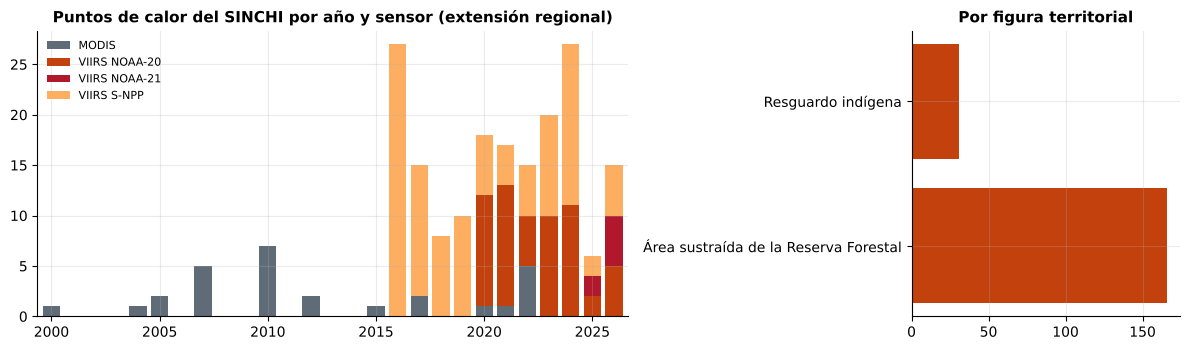

In [6]:
sinchi = fuentes.siatac("siatac_puntos_calor")
sinchi["anio"] = sinchi["acq_date"].dt.year
sinchi[["instrument", "leyenda"]] = sinchi[["instrument", "leyenda"]].replace(pi["etiquetas_siatac"])
anios_s = range(int(sinchi["anio"].min()), int(sinchi["anio"].max()) + 1)
por_sensor = sinchi.groupby(["anio", "instrument"]).size().unstack(fill_value=0).reindex(anios_s, fill_value=0)
fig, ax = plt.subplots(1, 2, figsize=(12, 3.6), gridspec_kw={"width_ratios": [2.2, 1]})
por_sensor.plot.bar(stacked=True, ax=ax[0], width=0.8, color=[viz.GRIS, viz.CALOR, viz.ROJO, "#fdae61"][:por_sensor.shape[1]])
ax[0].set_xticks(range(0, len(anios_s), 5)); ax[0].set_xticklabels(list(anios_s)[::5], rotation=0)
ax[0].set_xlabel("")
ax[0].legend(fontsize=8)
ax[0].set_title("Puntos de calor del SINCHI por año y sensor (extensión regional)")
figura = sinchi["leyenda"].fillna("sin figura").value_counts()
ax[1].barh(figura.index, figura.values, color=viz.CALOR)
ax[1].set_title("Por figura territorial")
fig.tight_layout()
ultimo = sinchi["acq_date"].max()
comun = range(2012, 2026)
display(Markdown(f"Puntos de calor del SINCHI en la extensión: **{len(sinchi)}** ({sinchi['acq_date'].min():%Y}–{ultimo:%d-%m-%Y}); "
                 f"en {ultimo:%Y}, **{int((sinchi['anio'] == ultimo.year).sum())}** hasta el {ultimo:%d-%m-%Y}. En 2012–2025 el SINCHI registra "
                 f"{int(por_sensor.loc[list(comun)].sum().sum())} puntos, frente a {int(anual.loc[list(comun), 'VIIRS (375 m)'].sum())} focos VIIRS de "
                 "FIRMS filtrados por confianza. Años con más puntos: "
                 + ", ".join(f"{a} ({v})" for a, v in por_sensor.sum(axis=1).nlargest(3).items()) + "."))

Cicatrices de quema cartografiadas en la extensión: 41 , con 204 ha en total.

cicatrices  area_ha
por año               2018                                         3.00     6.50
                      2019                                        16.00    70.00
                      2020                                         9.00    27.20
                      2021                                         3.00    70.80
                      2023                                         6.00    18.80
                      2025                                         4.00    10.50
por cobertura quemada Bosque                                        NaN    29.20
                      Otras coberturas                              NaN   129.60
                      Vegetación secundaria o en transición         NaN    45.00

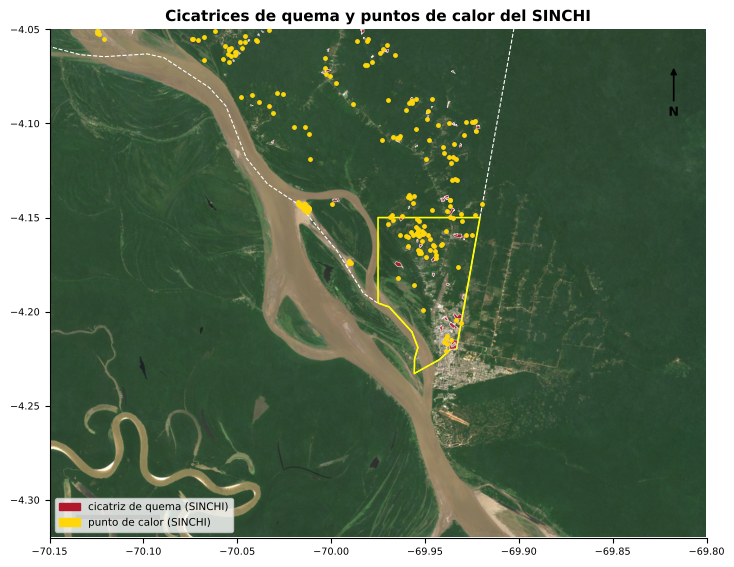

In [7]:
ciq = fuentes.siatac("siatac_cicatrices")
fig, ax = plt.subplots(figsize=(9, 6.6))
viz.fondo(ax, "bbox_regional")
mun.boundary.plot(ax=ax, color="white", lw=0.8, ls="--", zorder=2)
urbana.to_crs(4326).boundary.plot(ax=ax, color="yellow", lw=1.2, zorder=3)
if len(ciq):
    ciq.plot(ax=ax, color=viz.ROJO, edgecolor="white", lw=0.4, alpha=0.85, zorder=4)
sinchi.plot(ax=ax, color="#ffd60a", markersize=6, zorder=5)
ax.legend(handles=[Patch(color=viz.ROJO, label="cicatriz de quema (SINCHI)"), Patch(color="#ffd60a", label="punto de calor (SINCHI)")],
          loc="lower left", fontsize=7.5, frameon=True)
viz.marco(ax, "bbox_regional", "Cicatrices de quema y puntos de calor del SINCHI")
tabla_ciq = ciq.groupby("periodo").agg(cicatrices=("area_hectareas", "size"), area_ha=("area_hectareas", "sum"))
display(Markdown(f"Cicatrices de quema cartografiadas en la extensión: **{len(ciq)}**, con **{ciq['area_hectareas'].sum():.0f} ha** en total."))
display(pd.concat([tabla_ciq, ciq.groupby("categoria")["area_hectareas"].sum().rename("area_ha").to_frame()], keys=["por año", "por cobertura quemada"]).round(1))

In [8]:
viz.pie(viz.nota_fuente("siatac_puntos_calor", "siatac_cicatrices"))

Fuente: Instituto SINCHI – SIAT-AC (a partir de NASA FIRMS) — Puntos de calor por región (histórico), MODIS y VIIRS (S-NPP, NOAA-20, NOAA-21); Instituto SINCHI – SIAT-AC — Cicatrices de quema por región (histórico), escala 1:100.000.

**Lectura.** El SINCHI registra cerca del doble de puntos que los focos de FIRMS filtrados por confianza, porque
incluye todas las detecciones y los satélites NOAA-20 y NOAA-21; los años con más fuego coinciden en ambas fuentes
(2016, 2023 y 2024). De los 197 puntos, 166 caen en áreas sustraídas de la Reserva Forestal de la Amazonia, donde
están la ciudad, la carretera y las chagras, y 31 en resguardos indígenas. En 2026, hasta octubre, el lado
colombiano suma 15 puntos, cerca de la mediana de 2016–2025 (16), coherente con un TNA casi normal en marzo–mayo
([3.5.d](d_escenarios.ipynb)). Las cicatrices de quema suman unas 200 ha en 2018–2025, casi todas en áreas
sustraídas: el fuego quema sobre todo coberturas que no son bosque (otras coberturas, 130 ha, y vegetación
secundaria, 45 ha) y en menor medida bosque (29 ha).

## 4. Pérdida de cobertura arbórea

Pérdida acumulada 2001–2024 en la extensión regional dentro de Colombia: 2.918 ha ; últimos cinco años: 819 ha.

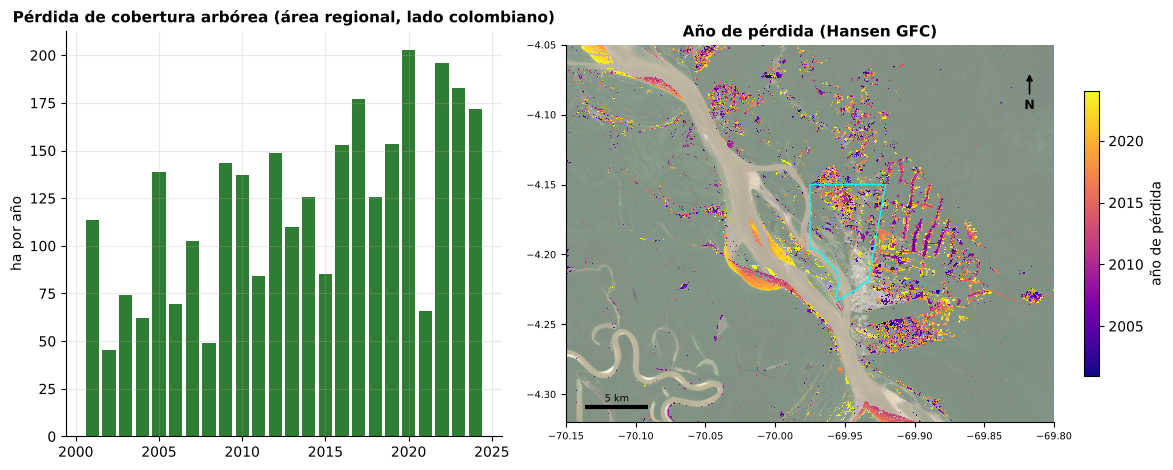

In [9]:
loss = fuentes.bosque_hansen("lossyear")
tc = fuentes.bosque_hansen("treecover2000")
dentro = loss.rio.write_crs(4326).rio.clip(mun.geometry, drop=False)
px_ha = (0.00025 * 111320) ** 2 * np.cos(np.radians(4.2)) / 1e4
por_anio = pd.Series(dentro.values.ravel()).value_counts().drop(0, errors="ignore").sort_index() * px_ha
por_anio.index = por_anio.index.astype(int) + 2000
fig, ax = plt.subplots(1, 2, figsize=(12, 4.8), gridspec_kw={"width_ratios": [1, 1.4]})
ax[0].bar(por_anio.index, por_anio, color=viz.VERDE)
ax[0].set_ylabel("ha por año")
ax[0].set_title("Pérdida de cobertura arbórea (área regional, lado colombiano)")
viz.fondo(ax[1], "bbox_regional", alfa=0.6)
v = loss.where(loss > 0)
im = ax[1].imshow(v.values + 2000, extent=(float(loss.x.min()), float(loss.x.max()), float(loss.y.min()), float(loss.y.max())), cmap="plasma",
                  vmin=2001, vmax=2024, zorder=2, interpolation="nearest")
urbana.to_crs(4326).boundary.plot(ax=ax[1], color="cyan", lw=1, zorder=3)
fig.colorbar(im, ax=ax[1], shrink=0.7, label="año de pérdida")
viz.marco(ax[1], "bbox_regional", "Año de pérdida (Hansen GFC)")
fig.tight_layout()
display(Markdown(f"Pérdida acumulada 2001–2024 en la extensión regional dentro de Colombia: **{por_anio.sum():,.0f} ha**; "
                 f"últimos cinco años: {por_anio.loc[2020:].sum():,.0f} ha.".replace(",", ".")))

In [10]:
viz.pie(viz.nota_fuente("perdida_bosque") + " Hansen et al. (2013).")

Fuente: Hansen et al. / University of Maryland – Global Forest Change — GFC v1.12 (2001–2024): treecover2000, lossyear. Hansen et al. (2013).

## 5. Sequía y fuego

Correlación de Spearman entre focos anuales y SPEI-3 de octubre (2012–2025): -0.54 .

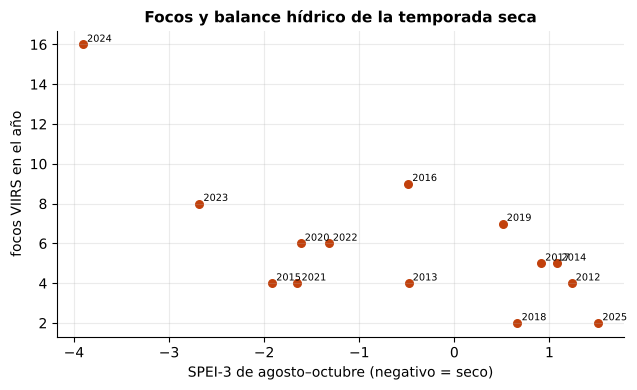

In [11]:
era = fuentes.clima_diario().loc["2001":]
spei3 = clima.balance_hidrico_spei(era["precipitation_sum"], era["et0_fao_evapotranspiration"], 3, base=(2001, 2020))
spei_sep = spei3[spei3.index.month == 10]
spei_sep.index = spei_sep.index.year
df = pd.concat({"focos_viirs": anual["VIIRS (375 m)"], "spei3_oct": spei_sep}, axis=1).dropna()
fig, ax = plt.subplots(figsize=(6.5, 4))
ax.scatter(df["spei3_oct"], df["focos_viirs"], color=viz.CALOR, s=30)
for a, r_ in df.iterrows():
    ax.annotate(str(a), (r_["spei3_oct"], r_["focos_viirs"]), fontsize=7, xytext=(3, 2), textcoords="offset points")
ax.set_xlabel("SPEI-3 de agosto–octubre (negativo = seco)")
ax.set_ylabel("focos VIIRS en el año")
ax.set_title("Focos y balance hídrico de la temporada seca")
fig.tight_layout()
r = df.corr(method="spearman").iloc[0, 1]
display(Markdown(f"Correlación de Spearman entre focos anuales y SPEI-3 de octubre (2012–2025): **{r:.2f}**."))

**Lectura.** Los años con temporada seca más deficitaria tienden a tener más focos. La relación entre sequía, deforestación y fuego es la sinergia
que el Panel Científico por la Amazonía identifica como el mayor riesgo para el bosque y la salud: el humo de
2023–2024 afectó la calidad del aire en ciudades de toda la cuenca [@costa2023spa; @marengo2024spa].